In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import random

In [4]:
file = './data/mnist_train.csv'
df = pd.read_csv(file)
df.shape

(59999, 785)

In [5]:
df.head(2)

,5,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.608,0.609,0.610,0.611,0.612,0.613,0.614,0.615,0.616,0.617
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df.iloc[1,:].max()

np.int64(255)

In [7]:
def data_loader(file):
    df = pd.read_csv(file)
    x = (df.iloc[:, 1:]/255.0).to_numpy()
    y = df.iloc[:, 0].to_numpy()
    return (x, y)

In [8]:
x_train, y_train = data_loader(file)
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(59999, 784))

In [9]:
y_train

array([0, 4, 1, ..., 5, 6, 8], shape=(59999,))

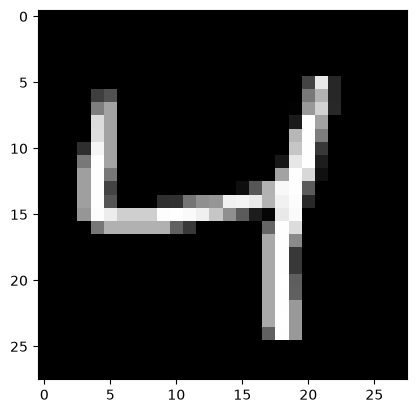

In [10]:
example_to_draw = x_train[1, :].reshape(28,28)
plt.imshow(example_to_draw, cmap='gray')
plt.show()

In [11]:
test_labels = [8, 4]
indices = np.where(np.isin(y_train, test_labels))[0]

x = x_train[indices]
y = y_train[indices]

y[y == test_labels[0]] = 0
y[y == test_labels[1]] = 1


In [12]:
m = x.shape[1]

w = np.random.rand(m)
b = np.random.rand()

In [13]:
def check_random_pred_result(n):
    """随机抽 n 个在 0 和 len(x)+ 1 之间的整数，比较真实结果和基于 w, b 的预测结果
    """
    rand_idxs = random.sample(range(0, len(x) + 1), n)
    for i in rand_idxs:
        h = x[i, :]@w + b
        a = str(1/(1+np.exp(-h)))
        result = str(y[i])
        print("Actual result is "+ result + ", prediction is " + a)

In [14]:
check_random_pred_result(10)

Actual result is 0, prediction is 1.0
Actual result is 1, prediction is 1.0
Actual result is 1, prediction is 0.9999999999999998
Actual result is 1, prediction is 0.9999999999989779
Actual result is 0, prediction is 1.0
Actual result is 0, prediction is 1.0
Actual result is 0, prediction is 1.0
Actual result is 0, prediction is 1.0
Actual result is 1, prediction is 1.0
Actual result is 1, prediction is 1.0


In [33]:
epochs = 20 # 调整轮次
alpha = 1 # 步长 步长一般是0.01这种量级，这里数据特殊所以比较大
loss_prev = 10e6 # 初始化一个很大的损失

w = np.random.rand(m) # 随机w权重和b权重
b = np.random.rand() 

for epoch in range (epochs):
    # x: n * 784, w:784 * 1, b:1
    # h: n * 1
    a = x@w + b

    # a: n * 1 n个样本
    a = 1 / (1 + np.exp(-a))

    # 避免log(0)的情况
    a = np.clip(a, .001, .999)

    # y: n * 1, a - y: n * 1, x.T: 784 * n
    # w: 784 * 1
    # y: n * 1, a - y: n * 1, x.T: 784 * n
    # w: 784 * 1
    w -= alpha * (x.T@(a-y)) / len(y) # T是转置，因为w是784个参数 后面这个就是梯度
    
    # 所有数据针对 b 的梯度下降取平均值，因为a 和 y是个向量
    b -= alpha * np.mean(a - y)

    loss = - np.sum(y*np.log(a) + (1-y)*np.log(1-a))
    loss_reduction = loss_prev - loss
    loss_prev = loss

    accuracy = sum((a > 0.5).astype(int) == y) / len(y)

    print('第', epoch+1, '轮', ' 损失为 {:.7}'.format(loss), \
          ' 该轮中损失减少了 {:.7}'.format(loss_reduction), \
          ' 正确识别率为 {:.4%}'.format(accuracy)
        )

第 1 轮  损失为 40423.12  该轮中损失减少了 9.959577e+06  正确识别率为 49.9615%
第 2 轮  损失为 40422.38  该轮中损失减少了 0.7435969  正确识别率为 49.9615%
第 3 轮  损失为 15959.55  该轮中损失减少了 24462.83  正确识别率为 66.5954%
第 4 轮  损失为 14788.46  该轮中损失减少了 1171.084  正确识别率为 69.3663%
第 5 轮  损失为 9656.029  该轮中损失减少了 5132.434  正确识别率为 78.6197%
第 6 轮  损失为 9261.233  该轮中损失减少了 394.7956  正确识别率为 77.2171%
第 7 轮  损失为 6265.506  该轮中损失减少了 2995.727  正确识别率为 85.6153%
第 8 轮  损失为 5554.407  该轮中损失减少了 711.0995  正确识别率为 84.4180%
第 9 轮  损失为 4261.278  该轮中损失减少了 1293.129  正确识别率为 89.2329%
第 10 轮  损失为 3776.03  该轮中损失减少了 485.2482  正确识别率为 89.3612%
第 11 轮  损失为 3268.684  该轮中损失减少了 507.3458  正确识别率为 91.0887%
第 12 轮  损失为 2939.985  该轮中损失减少了 328.6988  正确识别率为 91.7301%
第 13 轮  损失为 2655.277  该轮中损失减少了 284.7079  正确识别率为 92.6195%
第 14 轮  损失为 2426.073  该轮中损失减少了 229.2038  正确识别率为 93.1840%
第 15 轮  损失为 2234.767  该轮中损失减少了 191.3068  正确识别率为 93.6629%
第 16 轮  损失为 2075.284  该轮中损失减少了 159.4826  正确识别率为 94.1846%
第 17 轮  损失为 1939.318  该轮中损失减少了 135.9657  正确识别率为 94.5608%
第 18 轮  损失为 1823.234  该轮中损失减少了 116.0

In [34]:
x_test, y_test = data_loader('./data/mnist_test.csv')

In [35]:
test_labels = [8, 4]
indices = np.where(np.isin(y_test, test_labels))[0]

x = x_test[indices]
y = y_test[indices]

# 如果数字是 8， 我们把它变成 0
y[y == test_labels[0]] = 0

# 如果数字是 4， 我们把它变成 1
y[y == test_labels[1]] = 1

In [36]:
h = x@w + b
a = 1/(1+np.exp(-h))
accuracy = sum((a > 0.5).astype(int) == y)/len(y)
print(' 正确识别率为 {:.4%}'.format(accuracy))

 正确识别率为 96.2679%


In [16]:
x[0, :]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     